<a href="https://colab.research.google.com/github/Venkata-Prabhath/CNN_based-crowd-prediction/blob/main/Crowd_Risk_XAI_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Comparative Evaluation of Deep Learning Models for Crowd Counting

This notebook trains five adapted density-regression models on ShanghaiTech Part A. It uses one fixed train/validation split, repeats training with multiple initialization seeds, selects checkpoints by validation count MAE, and evaluates on the held-out test set. Metrics and plots are created only when the notebook runs; no experiment results are prefilled. The five-seed run can take several hours and requires persistent storage if you want to retain checkpoints.

**Colab:** choose Runtime ? Change runtime type ? a GPU runtime, then run cells from top to bottom. The dataset is not bundled. The data setup cell explains how to upload or mount it.

The Green/Yellow/Red labels are configurable illustrative count bands, not a trained risk classifier or validated safety limits. Do not use them for operational safety decisions without venue-specific evidence.


## 1. Install and import dependencies

Run this cell in Colab. TensorFlow is installed if needed; LIME and SHAP are optional for the explanation section. The core training workflow will stop with a clear error if a required package cannot be imported.

In [1]:
%pip -q install scipy opencv-python-headless pandas matplotlib scikit-learn kaggle
%pip -q install lime shap
import os, sys, json, time, random, platform, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import scipy.io
import matplotlib.pyplot as plt
import tensorflow as tf
from scipy.ndimage import gaussian_filter
from sklearn.model_selection import train_test_split

print('Python:', sys.version.split()[0], '| TensorFlow:', tf.__version__)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Python: 3.13.16 | TensorFlow: 2.21.0


## 2. Environment, GPU, reproducibility, and configuration

The notebook defaults to five initialization seeds on the same fixed split. This provides a first estimate of run-to-run variation; increase the number of seeds for stronger estimates. Five backbones across five seeds can take several hours and use substantial storage. For a quick smoke run, temporarily set `RUN_SEEDS = [42]`, then restore multiple seeds before reporting results. Mixed precision is off to preserve stable density sums.


In [2]:
SPLIT_SEED = 42
RUN_SEEDS = [42, 43, 44, 45, 46]
SEED = RUN_SEEDS[0]
IMAGE_SIZE = 256
DENSITY_SIZE = 64
BATCH_SIZE = 2  # reduce to 1 if GPU memory is insufficient
EPOCHS = 10
PATIENCE = 5
VALIDATION_FRACTION = 0.20
LEARNING_RATE = 1e-4
TIMING_REPEATS = 5
DATASET_RELEASE = 'Kaggle tthien/shanghaitech; downloaded release not recorded'
DATASET_LICENSE_STATUS = 'Check Kaggle data card before redistribution'
MODELS = ['MCNN', 'CSRNet', 'ResNet50', 'EfficientNetB0', 'MobileNetV2']
SNAPSHOT_EPOCHS = {1, 3, 5, 10}
GREEN_MAX, YELLOW_MAX = 100.0, 300.0  # illustrative count thresholds; document venue-specific rationale

random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
try: tf.config.experimental.enable_op_determinism()
except Exception as e: print('Deterministic ops unavailable:', e)
gpus = tf.config.list_physical_devices('GPU')
for gpu in gpus:
    try: tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError: pass
print('GPU devices:', gpus or 'None (CPU mode; training may be slow)')
print('Initialization seeds:', RUN_SEEDS, '| fixed split seed:', SPLIT_SEED)
if len(RUN_SEEDS) < 2: print('WARNING: a single seed does not estimate run-to-run variability.')
if len(set(RUN_SEEDS)) != len(RUN_SEEDS): raise ValueError('RUN_SEEDS must not contain duplicates')
if GREEN_MAX >= YELLOW_MAX: raise ValueError('GREEN_MAX must be lower than YELLOW_MAX')


GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Initialization seeds: [42, 43, 44, 45, 46] | fixed split seed: 42


## 3. Download ShanghaiTech Part A from Kaggle securely

This notebook defaults to the Kaggle dataset `tthien/shanghaitech` (a commonly used ShanghaiTech mirror). Review its data card and terms before using it; if your intended Kaggle dataset is different, replace `KAGGLE_DATASET` with the `owner/dataset-slug` shown in its Kaggle URL. Kaggle may require you to sign in and accept the dataset terms first.

Credentials are not embedded in this notebook. In Colab, the preferred option is to add `KAGGLE_USERNAME` and `KAGGLE_KEY` in **Secrets** (key icon) and grant this notebook access. Alternatively, upload your `kaggle.json` when prompted. Your local `kaggle.json` is not automatically transferred when you upload the notebook. The cell reads credentials into runtime environment variables without printing them, and removes an uploaded temporary key file after reading it. Never share or commit your Kaggle key.

The downloader handles nested Kaggle folder layouts and locates the folder containing both train and test image/annotation directories. If you already placed the dataset in Drive, set `DATA_ROOT` below to its `part_A` or `part_A_final` folder and the download is skipped.

In [3]:
# Optional: mount Google Drive if you want persistent data/results there.
# from google.colab import drive
# drive.mount('/content/drive')

SEED=42
IMAGE_SIZE=256
DENSITY_SIZE=64
BATCH_SIZE=2  # use 1 if the GPU runs out of memory
EPOCHS=10
PATIENCE=5
VALIDATION_FRACTION=0.20
LEARNING_RATE=1e-4
MODELS=['MCNN','CSRNet','ResNet50','EfficientNetB0','MobileNetV2']
SNAPSHOT_EPOCHS={1,3,5,10}
GREEN_MAX,YELLOW_MAX=100.0,300.0  # illustrative only; choose justified venue-specific thresholds

random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
try: tf.config.experimental.enable_op_determinism()
except Exception as e: print('Deterministic operations unavailable:',e)
gpus=tf.config.list_physical_devices('GPU')
for gpu in gpus:
    try: tf.config.experimental.set_memory_growth(gpu,True)
    except RuntimeError: pass
print('GPU devices:',gpus or 'None (CPU mode; training may be slow)')
if GREEN_MAX>=YELLOW_MAX: raise ValueError('GREEN_MAX must be lower than YELLOW_MAX')

# Set DATA_ROOT to an existing extracted folder to skip Kaggle download.
DATA_ROOT=Path('/content/data/ShanghaiTech/part_A')
KAGGLE_DATASET='tthien/shanghaitech'  # change to owner/dataset-slug if using a different Kaggle dataset
DOWNLOAD_DIR=Path('/content/kaggle_shanghaitech')
OUTPUT_DIR=Path('/content/crowd_risk_xai_results')  # for persistence, use /content/drive/MyDrive/...
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
print('Configured Kaggle dataset:',KAGGLE_DATASET)
print('Output directory:',OUTPUT_DIR)


GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Configured Kaggle dataset: tthien/shanghaitech
Output directory: /content/crowd_risk_xai_results


In [4]:
import os, subprocess, stat

def _locate_dataset_root(search_root):
    search_root=Path(search_root)
    if not search_root.exists(): return None
    for image_dir in search_root.rglob('train_data/images'):
        candidate=image_dir.parent.parent
        if (candidate/'train_data/ground-truth').is_dir() and (candidate/'test_data/images').is_dir() and (candidate/'test_data/ground-truth').is_dir():
            return candidate
    return None

def _get_kaggle_credentials():
    # Colab Secrets are preferable: values are never written to a key file or shown.
    try:
        from google.colab import userdata
        username=userdata.get('KAGGLE_USERNAME')
        key=userdata.get('KAGGLE_KEY')
        if username and key: return username,key
    except Exception:
        pass
    # Common paths if kaggle.json was uploaded or copied into the runtime.
    candidates=[Path('/content/kaggle.json'),Path.cwd()/'kaggle.json',Path.home()/'.kaggle/kaggle.json']
    for path in candidates:
        if path.is_file():
            try:
                data=json.loads(path.read_text(encoding='utf-8'))
                username,key=data.get('username'),data.get('key')
                if username and key:
                    if str(path).startswith('/content/') and path.name=='kaggle.json':
                        try: path.unlink()
                        except OSError: pass
                    return username,key
            except Exception as e:
                raise ValueError(f'Could not parse Kaggle credentials file at {path}. Verify kaggle.json format.') from e
    # Manual fallback: upload the kaggle.json file from your computer.
    try:
        from google.colab import files
    except ImportError as e:
        raise RuntimeError('Kaggle credentials not found. In Colab, add KAGGLE_USERNAME and KAGGLE_KEY in Secrets or upload kaggle.json.') from e
    uploaded=files.upload()
    keyfiles=[(name,blob) for name,blob in uploaded.items() if Path(name).name=='kaggle.json']
    if not keyfiles: raise RuntimeError('No kaggle.json uploaded. Add Colab Secrets or rerun this cell and upload the file.')
    try: data=json.loads(keyfiles[0][1].decode('utf-8'))
    except Exception as e: raise ValueError('Uploaded kaggle.json is invalid JSON.') from e
    username,key=data.get('username'),data.get('key')
    if not username or not key: raise ValueError('Uploaded kaggle.json must contain username and key fields.')
    return username,key

found=_locate_dataset_root(DATA_ROOT)
if found:
    DATA_ROOT=found
    print('Using existing ShanghaiTech dataset:',DATA_ROOT)
else:
    kaggle_user,kaggle_key=_get_kaggle_credentials()
    os.environ['KAGGLE_USERNAME']=str(kaggle_user); os.environ['KAGGLE_KEY']=str(kaggle_key)
    del kaggle_user,kaggle_key
    DOWNLOAD_DIR.mkdir(parents=True,exist_ok=True)
    cmd=['kaggle','datasets','download','-d',KAGGLE_DATASET,'-p',str(DOWNLOAD_DIR),'--unzip']
    print('Downloading and extracting the configured Kaggle dataset...')
    result=subprocess.run(cmd,text=True,capture_output=True)
    # Do not expose CLI output that could contain account or request details.
    if result.returncode!=0:
        detail=(result.stderr or result.stdout or 'No error details returned').strip().splitlines()[-1]
        raise RuntimeError(f'Kaggle download failed ({detail}). Check the dataset slug, internet access, Kaggle credentials, and whether you accepted the dataset terms.')
    found=_locate_dataset_root(DOWNLOAD_DIR)
    if not found:
        examples=[str(x.relative_to(DOWNLOAD_DIR)) for x in list(DOWNLOAD_DIR.rglob('train_data'))[:5]]
        raise FileNotFoundError(f'Download completed but expected ShanghaiTech Part A folder structure was not found under {DOWNLOAD_DIR}. train_data folders found: {examples}')
    DATA_ROOT=found
    # Remove credentials from the runtime environment after download.
    os.environ.pop('KAGGLE_USERNAME',None); os.environ.pop('KAGGLE_KEY',None)
    print('Dataset downloaded and located at:',DATA_ROOT)
print('Resolved dataset root:',DATA_ROOT.resolve())


Saving kaggle.json to kaggle.json
Dataset downloaded and located at: /content/kaggle_shanghaitech/shanghaitech_h5_empty/ShanghaiTech/part_A
Resolved dataset root: /content/kaggle_shanghaitech/shanghaitech_h5_empty/ShanghaiTech/part_A


## 4. Load and validate image/annotation pairs and fixed splits

Each JPG must have its matching MATLAB annotation. This parser expects the common ShanghaiTech Part A `image_info` head-point field and rejects unsupported structures, invalid coordinates, unreadable images, and empty splits. Train/validation partition is fixed and recorded; test is held out.

In [5]:
def paired_paths(root, split):
    base = Path(root) / f'{split}_data'
    image_dir, gt_dir = base/'images', base/'ground-truth'
    if not image_dir.is_dir() or not gt_dir.is_dir():
        raise FileNotFoundError(f'Missing expected folders: {image_dir} and/or {gt_dir}. Check DATA_ROOT.')
    pairs=[]
    for image in sorted(image_dir.glob('*.jpg')):
        gt=gt_dir/(image.stem.replace('IMG_', 'GT_IMG_')+'.mat')
        if not gt.is_file(): raise FileNotFoundError(f'Missing annotation for {image}: {gt}')
        pairs.append((image,gt))
    if not pairs: raise FileNotFoundError(f'No JPG images in {image_dir}')
    return pairs

def load_pair(pair):
    image_path, mat_path = pair
    bgr=cv2.imread(str(image_path))
    if bgr is None: raise ValueError(f'Unreadable image: {image_path}')
    image=cv2.cvtColor(bgr,cv2.COLOR_BGR2RGB)
    mat=scipy.io.loadmat(str(mat_path))
    try: points=np.asarray(mat['image_info'][0,0][0,0][0],dtype=np.float32).reshape(-1,2)
    except (KeyError,IndexError,TypeError,ValueError) as e: raise ValueError(f'Unsupported annotation format: {mat_path}') from e
    h,w=image.shape[:2]
    if not np.isfinite(points).all(): raise ValueError(f'Non-finite points: {mat_path}')
    if points.size and ((points[:,0]<0).any() or (points[:,0]>=w).any() or (points[:,1]<0).any() or (points[:,1]>=h).any()):
        raise ValueError(f'Out-of-bounds points for {image_path} ({w}x{h})')
    return image,points

train_all=paired_paths(DATA_ROOT,'train'); test_pairs=paired_paths(DATA_ROOT,'test')
train_pairs,val_pairs=train_test_split(train_all,test_size=VALIDATION_FRACTION,random_state=SPLIT_SEED,shuffle=True)
if not train_pairs or not val_pairs or not test_pairs: raise ValueError('Train, validation, and test splits must all be nonempty.')
splits={'split_seed':SPLIT_SEED,'train':[str(p[0]) for p in train_pairs],'validation':[str(p[0]) for p in val_pairs],'test':[str(p[0]) for p in test_pairs]}
(OUTPUT_DIR/'splits.json').write_text(json.dumps(splits,indent=2))
print(f'Validated pairs: train={len(train_pairs)}, validation={len(val_pairs)}, test={len(test_pairs)}')


Validated pairs: train=240, validation=60, test=182


## 5. Generate density targets and verify their sums

Head points are placed on the original image grid and Gaussian-smoothed. We renormalize each target to preserve its annotated count, including near edges, then resize and renormalize again so the lower-resolution training target retains the same count. We check this invariant before training.

Validated density maps: 482 | count range: 33.0 to 3138.0


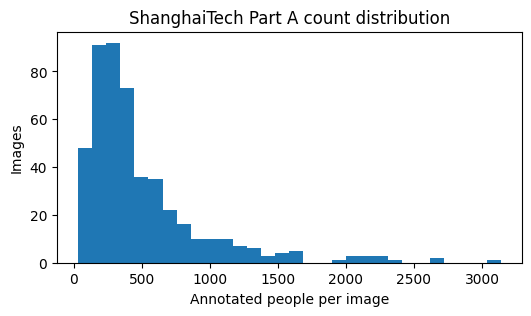

In [6]:
def density_from_points(shape, points, sigma=4.0):
    h,w=shape; d=np.zeros((h,w),np.float32)
    for x,y in points: d[int(y),int(x)]+=1.0
    d=gaussian_filter(d,sigma=sigma).astype(np.float32)
    if len(points) and d.sum()>0: d*=len(points)/float(d.sum())
    return d

def preprocess_image(image, model_name):
    im=cv2.resize(image,(IMAGE_SIZE,IMAGE_SIZE),interpolation=cv2.INTER_AREA).astype(np.float32)
    if model_name=='CSRNet': return tf.keras.applications.vgg16.preprocess_input(im)
    if model_name=='ResNet50': return tf.keras.applications.resnet50.preprocess_input(im)
    if model_name=='EfficientNetB0': return tf.keras.applications.efficientnet.preprocess_input(im)
    if model_name=='MobileNetV2': return tf.keras.applications.mobilenet_v2.preprocess_input(im)
    return im/255.0

def prepare(pair, model_name):
    image,points=load_pair(pair); count=float(len(points))
    d=density_from_points(image.shape[:2],points)
    target=cv2.resize(d,(DENSITY_SIZE,DENSITY_SIZE),interpolation=cv2.INTER_AREA).astype(np.float32)
    if target.sum()>0: target*=count/float(target.sum())
    if not np.isfinite(target).all() or abs(float(target.sum())-count)>1e-3: raise ValueError(f'Density mass mismatch: {pair[0]}')
    return preprocess_image(image,model_name),target[...,None],count,image,points,d

# Validate the full set's annotations and density mass; show distribution.
all_pairs=train_pairs+val_pairs+test_pairs
counts=[]
for pair in all_pairs:
    _,_,n,_,_,_=prepare(pair,'MCNN'); counts.append(n)
print('Validated density maps:',len(counts),'| count range:',min(counts),'to',max(counts))
plt.figure(figsize=(6,3)); plt.hist(counts,bins=30); plt.xlabel('Annotated people per image'); plt.ylabel('Images'); plt.title('ShanghaiTech Part A count distribution'); plt.show()

## 6. Model architectures and training batches

All models regress a nonnegative density map whose sum estimates count. MCNN uses three convolution branches with different receptive fields. CSRNet uses an ImageNet VGG16 front end and dilated convolution back end. ResNet50, EfficientNet-B0, and MobileNetV2 are ImageNet classification backbones with lightweight convolutional density heads. These are shared-protocol adaptations, not exact reproductions of each paper's canonical recipe. The output is resized to 64×64 for comparable training targets.

In [7]:
def make_model(name):
    inp=tf.keras.Input((IMAGE_SIZE,IMAGE_SIZE,3),name='rgb_image')
    if name=='MCNN':
        branches=[]
        for filters,kernel in ((16,9),(20,7),(24,5)):
            b=tf.keras.layers.Conv2D(filters,kernel,padding='same',activation='relu')(inp)
            b=tf.keras.layers.MaxPooling2D(2)(b)
            b=tf.keras.layers.Conv2D(filters*2,max(3,kernel-2),padding='same',activation='relu')(b); branches.append(b)
        x=tf.keras.layers.Concatenate()(branches)
        x=tf.keras.layers.Conv2D(64,3,padding='same',activation='relu')(x); x=tf.keras.layers.Conv2D(32,3,padding='same',activation='relu')(x)
    elif name=='CSRNet':
        backbone=tf.keras.applications.VGG16(include_top=False,weights='imagenet',input_tensor=inp)
        x=backbone.get_layer('block4_conv3').output
        for filters,dilation in ((512,2),(512,2),(256,2),(128,2),(64,1)):
            x=tf.keras.layers.Conv2D(filters,3,padding='same',dilation_rate=dilation,activation='relu')(x)
    else:
        app={'ResNet50':tf.keras.applications.ResNet50,'EfficientNetB0':tf.keras.applications.EfficientNetB0,'MobileNetV2':tf.keras.applications.MobileNetV2}[name]
        backbone=app(include_top=False,weights='imagenet',input_tensor=inp)
        x=backbone.output
        for f in (256,128,64): x=tf.keras.layers.Conv2D(f,3,padding='same',activation='relu')(x)
    x=tf.keras.layers.Conv2D(1,1,padding='same',activation='relu',name='density_native')(x)
    out=tf.keras.layers.Resizing(DENSITY_SIZE,DENSITY_SIZE,name='density_map')(x)
    return tf.keras.Model(inp,out,name=name)

def density_mse(y_true,y_pred): return tf.reduce_mean(tf.square(y_true-y_pred))
def batch_generator(pairs,name,shuffle=False):
    ids=np.arange(len(pairs)); rng=np.random.default_rng(SEED)
    while True:
        if shuffle: rng.shuffle(ids)
        for start in range(0,len(ids),BATCH_SIZE):
            batch=[prepare(pairs[i],name) for i in ids[start:start+BATCH_SIZE]]
            yield np.stack([b[0] for b in batch]),np.stack([b[1] for b in batch])

# Smoke-check every model's output shape and parameter count before full training.
for name in MODELS:
    m=make_model(name); print(name,m.output_shape,f'{m.count_params():,} parameters'); del m


MCNN (None, 64, 64, 1) 151,945 parameters
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
CSRNet (None, 64, 64, 1) 13,903,681 parameters
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
ResNet50 (None, 64, 64, 1) 28,675,457 parameters
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
EfficientNetB0 (None, 64, 64, 1) 7,367,844 parameters


/tmp/ipykernel_417/2819329050.py:18: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  backbone=app(include_top=False,weights='imagenet',input_tensor=inp)


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MobileNetV2 (None, 64, 64, 1) 5,576,257 parameters


## 7. Train all five models and save checkpoints

Each model uses the same fixed train/validation split and target construction. Validation MAE selects `best.keras`; test data is not used in selection. Epoch logs include density MSE losses, count MAE/RMSE, and elapsed time. Requested epoch snapshots are saved at 1, 3, 5, 10, and the final epoch when reached. Any non-finite loss, missing checkpoint, or unchanged trainable weights raises an error instead of reporting success. Checkpoints and logs are written under `OUTPUT_DIR/<model>/`.

In [8]:
def runtime_metadata():
    import scipy, sklearn
    try:
        import psutil
        memory_bytes=int(psutil.virtual_memory().total)
    except Exception:
        memory_bytes=None
    gpu_info=[]
    for device in tf.config.list_physical_devices('GPU'):
        try: details=tf.config.experimental.get_device_details(device)
        except Exception: details={}
        gpu_info.append({'device':device.name,**details})
    return {'python':sys.version.split()[0],'tensorflow':tf.__version__,'numpy':np.__version__,
            'scipy':scipy.__version__,'opencv':cv2.__version__,'pandas':pd.__version__,
            'scikit_learn':sklearn.__version__,'platform':platform.platform(),
            'logical_cpu_count':os.cpu_count(),'memory_bytes':memory_bytes,'gpus':gpu_info}

def count_metrics(model,pairs,name,timing_repeats=1):
    if timing_repeats < 1: raise ValueError('timing_repeats must be at least 1')
    truth=[]; pred=[]; durations=[]
    warm=prepare(pairs[0],name)[0]; _=model(warm[None],training=False).numpy()
    for pair in pairs:
        x,_,n,*_=prepare(pair,name); y=None
        for _ in range(timing_repeats):
            t=time.perf_counter(); y=model(x[None],training=False).numpy(); durations.append(time.perf_counter()-t)
        truth.append(n); pred.append(float(np.maximum(y,0).sum()))
    err=np.asarray(pred)-np.asarray(truth)
    return {'MAE':float(np.mean(np.abs(err))),'RMSE':float(np.sqrt(np.mean(err**2))),
            'seconds_per_image':float(np.mean(durations)),
            'seconds_per_image_std':float(np.std(durations,ddof=1)) if len(durations)>1 else 0.0,
            'truth':truth,'prediction':pred}

training_records_by_seed={}; model_metadata_by_seed={}; run_dirs={}
for run_seed in RUN_SEEDS:
    print(f'\n========== Initialization seed {run_seed} ==========')
    SEED=run_seed; random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
    try: tf.config.experimental.enable_op_determinism()
    except Exception: pass
    run_output=OUTPUT_DIR/f'seed_{run_seed}'; run_output.mkdir(parents=True,exist_ok=True); run_dirs[run_seed]=run_output
    records_for_seed={}; metadata_for_seed={}
    for name in MODELS:
        print('\n===== Training',name,'=====')
        folder=run_output/name; folder.mkdir(parents=True,exist_ok=True)
        model=make_model(name); initial=[w.numpy().copy() for w in model.trainable_weights]
        model.compile(optimizer=tf.keras.optimizers.Adam(LEARNING_RATE),loss=density_mse)
        rows=[]; best=float('inf'); best_epoch=None; start_all=time.perf_counter()
        steps=int(np.ceil(len(train_pairs)/BATCH_SIZE)); val_steps=int(np.ceil(len(val_pairs)/BATCH_SIZE))
        for epoch in range(1,EPOCHS+1):
            t0=time.perf_counter()
            hist=model.fit(batch_generator(train_pairs,name,True),steps_per_epoch=steps,validation_data=batch_generator(val_pairs,name,False),validation_steps=val_steps,epochs=1,verbose=2)
            train_loss=float(hist.history['loss'][-1]); val_loss=float(hist.history['val_loss'][-1])
            if not np.isfinite([train_loss,val_loss]).all(): raise FloatingPointError(f'Non-finite loss for {name}, epoch {epoch}')
            vm=count_metrics(model,val_pairs,name); row={'seed':run_seed,'epoch':epoch,'train_loss':train_loss,'validation_loss':val_loss,'validation_MAE':vm['MAE'],'validation_RMSE':vm['RMSE'],'epoch_seconds':time.perf_counter()-t0,'elapsed_training_seconds':time.perf_counter()-start_all}
            rows.append(row); pd.DataFrame(rows).to_csv(folder/'epochs.csv',index=False)
            if vm['MAE']<best:
                best=vm['MAE']; best_epoch=epoch; model.save(folder/'best.keras')
            if epoch in SNAPSHOT_EPOCHS or epoch==EPOCHS: model.save(folder/f'epoch_{epoch:03d}.keras')
            print(f'{name} seed {run_seed} epoch {epoch}: val MAE={vm["MAE"]:.3f}, RMSE={vm["RMSE"]:.3f}, elapsed={row["epoch_seconds"]:.1f}s')
            if epoch>=PATIENCE and rows[-1]['validation_loss'] >= min(r['validation_loss'] for r in rows[:-1])-1e-8 and (epoch-min(range(1,epoch+1),key=lambda k:rows[k-1]['validation_loss']))>=PATIENCE: break
        changed=any(not np.array_equal(a,w.numpy()) for a,w in zip(initial,model.trainable_weights))
        if not changed: raise RuntimeError(f'{name} seed {run_seed}: trainable weights did not change')
        if not (folder/'best.keras').is_file(): raise RuntimeError(f'{name} seed {run_seed}: best checkpoint missing')
        records_for_seed[name]=pd.DataFrame(rows); metadata_for_seed[name]={'best_epoch':best_epoch,'best_validation_MAE':best,'checkpoint':str(folder/'best.keras'),'weights_changed':changed}
        del model; tf.keras.backend.clear_session()
    training_records_by_seed[run_seed]=records_for_seed; model_metadata_by_seed[run_seed]=metadata_for_seed
    run_meta={'model_seed':run_seed,'split_seed':SPLIT_SEED,'epochs_budget':EPOCHS,'image_size':IMAGE_SIZE,'density_size':DENSITY_SIZE,'batch_size':BATCH_SIZE,'learning_rate':LEARNING_RATE,'validation_fraction':VALIDATION_FRACTION,'dataset_release':DATASET_RELEASE,'dataset_license_status':DATASET_LICENSE_STATUS,'models':MODELS,'risk_thresholds':{'green_lt':GREEN_MAX,'yellow_lt':YELLOW_MAX},'runtime':runtime_metadata()}
    (run_output/'experiment.json').write_text(json.dumps(run_meta,indent=2))

mean_validation={name:float(np.mean([model_metadata_by_seed[s][name]['best_validation_MAE'] for s in RUN_SEEDS])) for name in MODELS}
selection=min(mean_validation,key=mean_validation.get)
best_seed=min(RUN_SEEDS,key=lambda s:model_metadata_by_seed[s][selection]['best_validation_MAE'])
training_records=training_records_by_seed[best_seed]; model_metadata=model_metadata_by_seed[best_seed]
selection_record={'selection_rule':'lowest mean validation count MAE across initialization seeds','mean_validation_MAE_by_model':mean_validation,'selected_model':selection,'example_checkpoint_seed':best_seed,'split_seed':SPLIT_SEED,'runs':model_metadata_by_seed,'test_used_for_selection':False}
(OUTPUT_DIR/'selection.json').write_text(json.dumps(selection_record,indent=2))
print('Selected architecture by mean validation MAE:',selection,'| example checkpoint seed:',best_seed)



========== Initialization seed 42 ==========

===== Training MCNN =====
120/120 - 21s - 172ms/step - loss: 0.1244 - val_loss: 0.1176
MCNN seed 42 epoch 1: val MAE=294.805, RMSE=431.488, elapsed=24.2s
120/120 - 16s - 135ms/step - loss: 0.1154 - val_loss: 0.1121
MCNN seed 42 epoch 2: val MAE=248.761, RMSE=404.109, elapsed=19.8s
120/120 - 17s - 143ms/step - loss: 0.1115 - val_loss: 0.1097
MCNN seed 42 epoch 3: val MAE=238.556, RMSE=394.402, elapsed=21.5s
120/120 - 17s - 140ms/step - loss: 0.1097 - val_loss: 0.1098
MCNN seed 42 epoch 4: val MAE=264.798, RMSE=403.476, elapsed=20.4s
120/120 - 18s - 151ms/step - loss: 0.1074 - val_loss: 0.1083
MCNN seed 42 epoch 5: val MAE=252.857, RMSE=396.133, elapsed=21.8s
120/120 - 17s - 139ms/step - loss: 0.1055 - val_loss: 0.1070
MCNN seed 42 epoch 6: val MAE=244.008, RMSE=391.250, elapsed=20.4s
120/120 - 17s - 140ms/step - loss: 0.1034 - val_loss: 0.1053
MCNN seed 42 epoch 7: val MAE=226.063, RMSE=382.007, elapsed=20.3s
120/120 - 17s - 139ms/step - lo

/tmp/ipykernel_417/2819329050.py:18: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  backbone=app(include_top=False,weights='imagenet',input_tensor=inp)


120/120 - 42s - 353ms/step - loss: 0.1462 - val_loss: 0.1387
MobileNetV2 seed 42 epoch 1: val MAE=471.450, RMSE=633.060, elapsed=54.0s
120/120 - 19s - 159ms/step - loss: 0.1459 - val_loss: 0.1387
MobileNetV2 seed 42 epoch 2: val MAE=471.450, RMSE=633.060, elapsed=30.8s
120/120 - 19s - 159ms/step - loss: 0.1459 - val_loss: 0.1387
MobileNetV2 seed 42 epoch 3: val MAE=471.450, RMSE=633.060, elapsed=32.3s
120/120 - 19s - 159ms/step - loss: 0.1459 - val_loss: 0.1387
MobileNetV2 seed 42 epoch 4: val MAE=471.450, RMSE=633.060, elapsed=30.7s
120/120 - 19s - 156ms/step - loss: 0.1459 - val_loss: 0.1387
MobileNetV2 seed 42 epoch 5: val MAE=471.450, RMSE=633.060, elapsed=30.1s
120/120 - 19s - 157ms/step - loss: 0.1459 - val_loss: 0.1387
MobileNetV2 seed 42 epoch 6: val MAE=471.450, RMSE=633.060, elapsed=30.4s

========== Initialization seed 43 ==========

===== Training MCNN =====
120/120 - 18s - 150ms/step - loss: 0.1227 - val_loss: 0.1165
MCNN seed 43 epoch 1: val MAE=286.375, RMSE=426.371, ela

## 8. Test evaluation, consistency checks, tables, and plots

Reload each model's best validation-MAE checkpoint and evaluate exactly the same held-out test files. Timing excludes one warmup and measures model call time on one preprocessed image; preprocessing and disk access are excluded. Suspiciously identical prediction vectors trigger a prominent warning and are saved for inspection, never silently accepted as independent evidence.

,model,MAE_mean,MAE_std,RMSE_mean,RMSE_std,inference_seconds_per_image_mean,inference_seconds_per_image_std
0,CSRNet,433.307692,0.000000,559.188865,0.000000,0.035632,0.000707
1,EfficientNetB0,173.784564,8.522427,259.408531,9.452761,0.299241,0.009201
2,MCNN,181.159725,18.272810,262.831855,30.253559,0.018785,0.000154
3,MobileNetV2,433.307511,0.000406,559.188770,0.000212,0.155181,0.005391
4,ResNet50,381.467007,115.881566,493.960752,145.828888,0.231434,0.001992


/tmp/ipykernel_417/2422675312.py:27: UserWarning: SUSPICIOUS near-identical test prediction vectors by seed: [(42, 'CSRNet', 'ResNet50'), (42, 'CSRNet', 'MobileNetV2'), (42, 'ResNet50', 'MobileNetV2'), (43, 'CSRNet', 'ResNet50'), (43, 'CSRNet', 'MobileNetV2'), (43, 'ResNet50', 'MobileNetV2'), (45, 'CSRNet', 'ResNet50'), (45, 'CSRNet', 'MobileNetV2'), (45, 'ResNet50', 'MobileNetV2'), (46, 'CSRNet', 'MobileNetV2')]. Inspect training and checkpoints.
  if identical_pairs: warnings.warn(f'SUSPICIOUS near-identical test prediction vectors by seed: {identical_pairs}. Inspect training and checkpoints.')


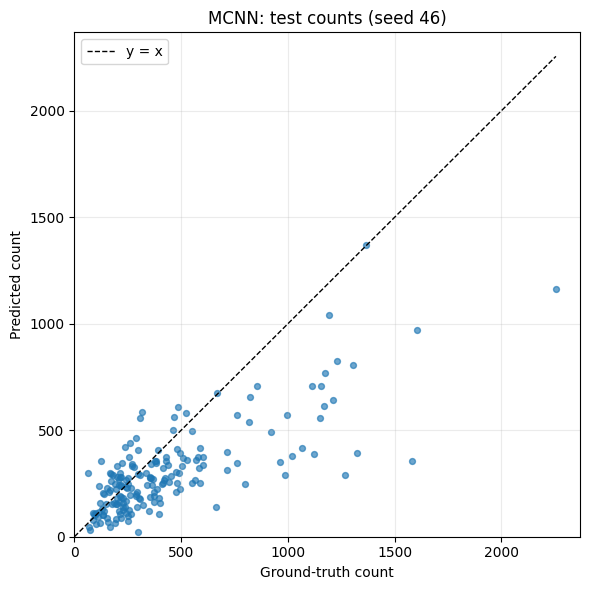

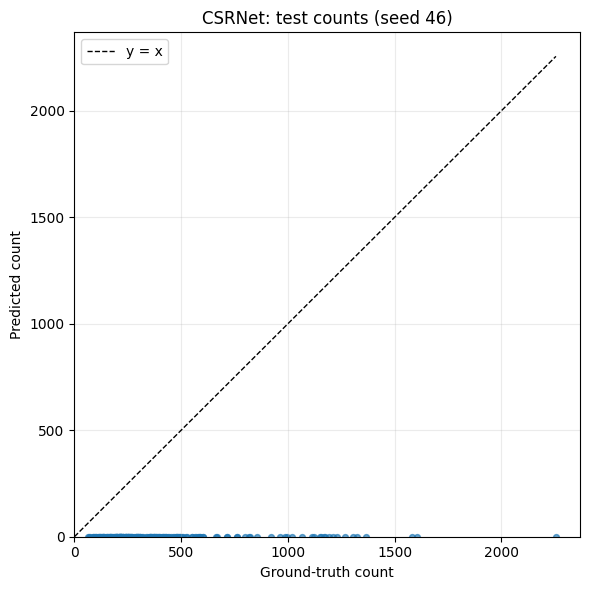

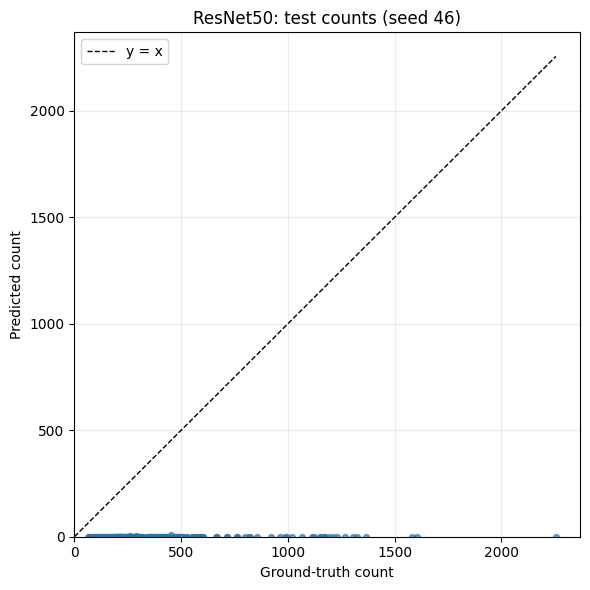

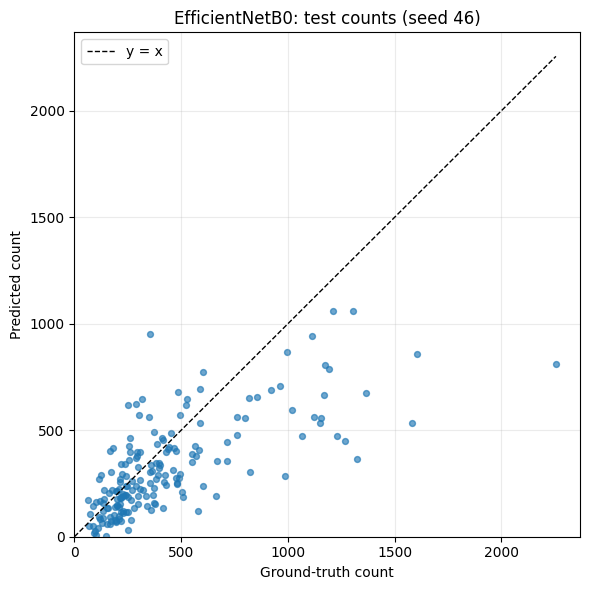

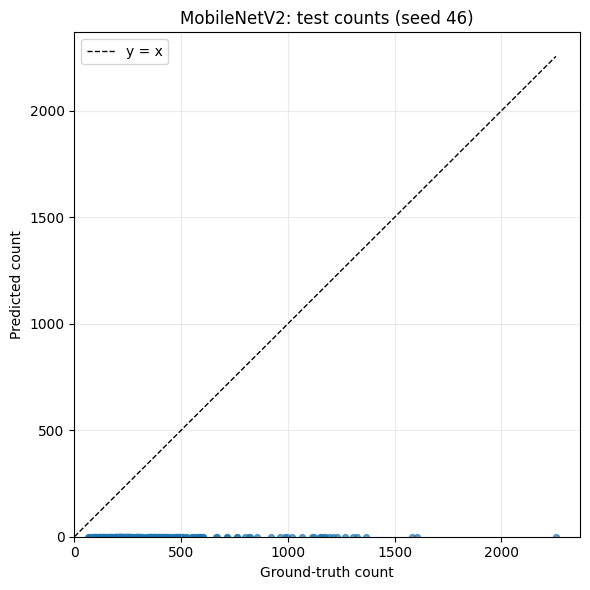

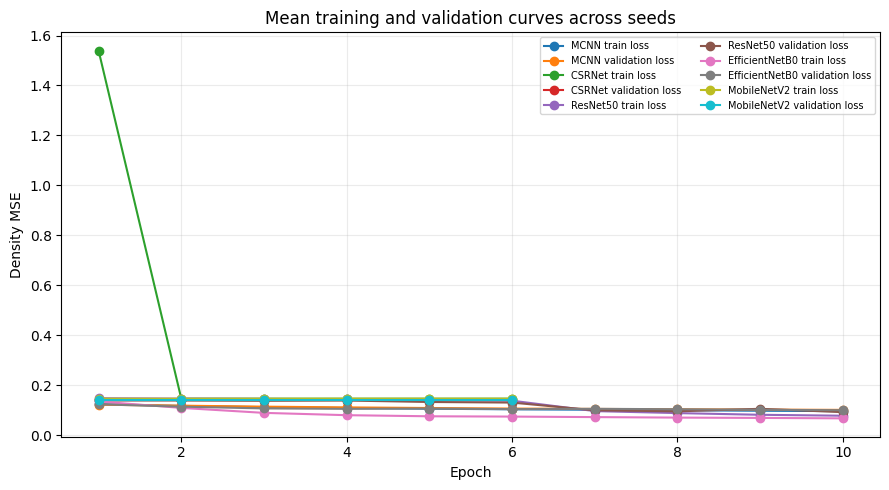

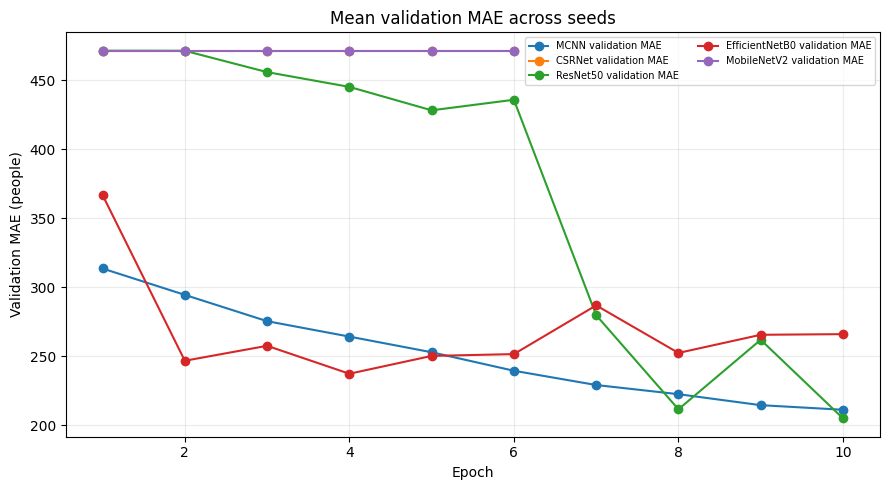

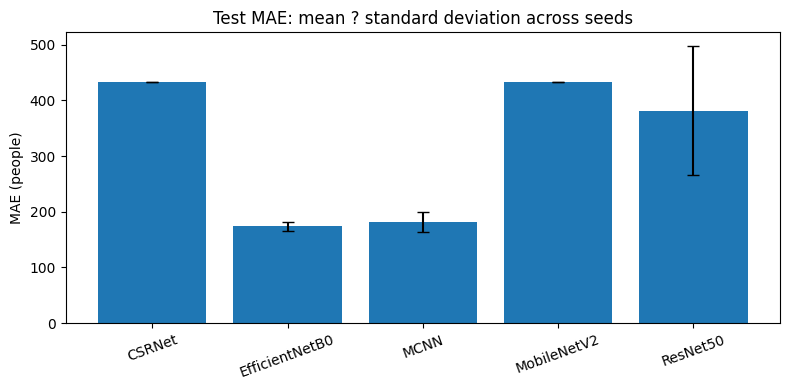

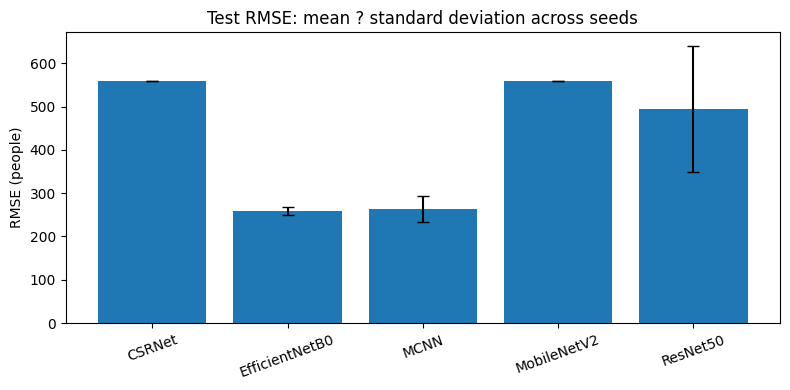

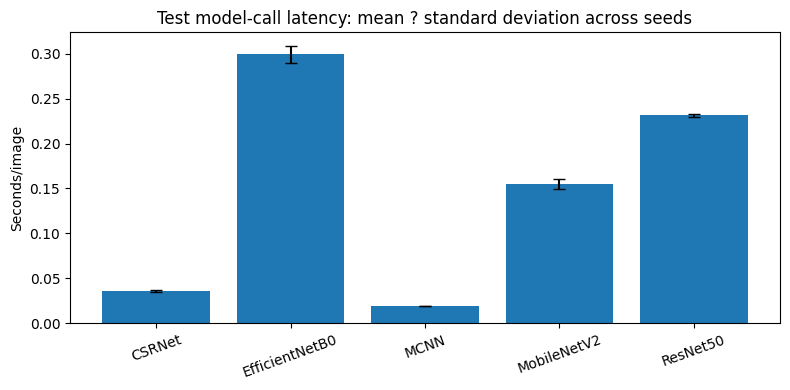

In [9]:
# Evaluate each seed on the same held-out test set. The test set never selects a model/checkpoint.
test_run_rows=[]; predictions_by_run={}; loaded_models={}
for run_seed in RUN_SEEDS:
    run_output=run_dirs[run_seed]
    for name in MODELS:
        model=tf.keras.models.load_model(run_output/name/'best.keras',custom_objects={'density_mse':density_mse})
        met=count_metrics(model,test_pairs,name,TIMING_REPEATS)
        test_run_rows.append({'seed':run_seed,'model':name,'MAE':met['MAE'],'RMSE':met['RMSE'],'inference_seconds_per_image':met['seconds_per_image'],'inference_seconds_std':met['seconds_per_image_std'],'prediction_mean':float(np.mean(met['prediction'])),'prediction_std':float(np.std(met['prediction'])),'prediction_min':float(np.min(met['prediction'])),'prediction_max':float(np.max(met['prediction']))})
        predictions_by_run[(run_seed,name)]={'truth':met['truth'],'prediction':met['prediction']}
        pd.DataFrame({'image':[str(p[0]) for p in test_pairs],'ground_truth_count':met['truth'],'predicted_count':met['prediction']}).to_csv(run_output/f'{name}_test_predictions.csv',index=False)
        # Retain one validation-selected checkpoint for qualitative figures/XAI.
        if run_seed==best_seed: loaded_models[name]=model
        else: del model
        tf.keras.backend.clear_session() if run_seed!=best_seed else None

per_seed_test_df=pd.DataFrame(test_run_rows); per_seed_test_df.to_csv(OUTPUT_DIR/'repeated_test_metrics_by_seed.csv',index=False)
agg=per_seed_test_df.groupby('model')[['MAE','RMSE','inference_seconds_per_image']].agg(['mean','std'])
agg.columns=[f'{metric}_{stat}' for metric,stat in agg.columns]
test_df=agg.reset_index(); test_df.to_csv(OUTPUT_DIR/'test_comparison.csv',index=False); display(test_df)

# Check near-identical prediction vectors within every seed.
identical_pairs=[]
for run_seed in RUN_SEEDS:
    for i,a in enumerate(MODELS):
        for b in MODELS[i+1:]:
            if np.allclose(predictions_by_run[(run_seed,a)]['prediction'],predictions_by_run[(run_seed,b)]['prediction'],rtol=1e-5,atol=1e-5): identical_pairs.append((run_seed,a,b))
if identical_pairs: warnings.warn(f'SUSPICIOUS near-identical test prediction vectors by seed: {identical_pairs}. Inspect training and checkpoints.')
else: print('Identical-prediction check: no pair of models has near-identical test count vectors.')

# Ground-truth-versus-predicted diagnostic plots for the selected validation checkpoint seed.
for name in MODELS:
    values=predictions_by_run[(best_seed,name)]; truth=np.asarray(values['truth']); pred=np.asarray(values['prediction'])
    fig,ax=plt.subplots(figsize=(6,6)); ax.scatter(truth,pred,s=18,alpha=.65)
    upper=float(max(truth.max(),pred.max(),1)); ax.plot([0,upper],[0,upper],'k--',linewidth=1,label='y = x')
    ax.set(xlabel='Ground-truth count',ylabel='Predicted count',title=f'{name}: test counts (seed {best_seed})'); ax.set_xlim(left=0); ax.set_ylim(bottom=0); ax.grid(alpha=.25); ax.legend(); fig.tight_layout(); fig.savefig(OUTPUT_DIR/f'{name}_test_scatter.png',dpi=220); plt.show()

# Mean training curves across seeds; standard deviations are retained in the per-seed logs.
for metric,ylabel,filename in [('loss','Density MSE','loss_curves.png'),('MAE','Validation MAE (people)','validation_mae.png')]:
    fig,ax=plt.subplots(figsize=(9,5))
    for name in MODELS:
        frames=[training_records_by_seed[s][name] for s in RUN_SEEDS]
        combined=pd.concat(frames,ignore_index=True); ycols=['train_loss','validation_loss'] if metric=='loss' else ['validation_MAE']
        for col in ycols:
            means=combined.groupby('epoch')[col].mean(); ax.plot(means.index,means.values,marker='o',label=f'{name} {col.replace("_"," ")}')
    ax.set(xlabel='Epoch',ylabel=ylabel,title='Mean training and validation curves across seeds' if metric=='loss' else 'Mean validation MAE across seeds'); ax.grid(alpha=.25); ax.legend(fontsize=7,ncol=2); fig.tight_layout(); fig.savefig(OUTPUT_DIR/filename,dpi=220); plt.show()

for metric,title,ylabel in [('MAE','Test MAE','MAE (people)'),('RMSE','Test RMSE','RMSE (people)'),('inference_seconds_per_image','Test model-call latency','Seconds/image')]:
    fig,ax=plt.subplots(figsize=(8,4)); means=test_df[f'{metric}_mean']; stds=test_df[f'{metric}_std'].fillna(0); ax.bar(test_df.model,means,yerr=stds,capsize=4); ax.set_ylabel(ylabel); ax.set_title(f'{title}: mean ? standard deviation across seeds'); ax.tick_params(axis='x',rotation=20); fig.tight_layout(); fig.savefig(OUTPUT_DIR/f'test_{metric}.png',dpi=220); plt.show()


## 9. Visualize predictions and apply documented count bands

Show original CCTV-style images, ground-truth density, selected model density, and count. Counts are sums of density outputs. Risk bands are applied only as illustrative thresholds after prediction; they are not learned labels, calibrated probabilities, or forecasts. Choose thresholds from a documented venue-specific policy before discussing operational risk.

In [ ]:
def risk_band(count): return 'Green' if count< GREEN_MAX else ('Yellow' if count<YELLOW_MAX else 'Red')
chosen=selection; chosen_model=loaded_models[chosen]
truth_counts=np.array([len(load_pair(p)[1]) for p in test_pairs]); order=np.argsort(truth_counts)
example_idx=sorted(set([int(order[0]),int(order[len(order)//2]),int(order[-1])]))
example_dir=OUTPUT_DIR/'representative_examples'; example_dir.mkdir(exist_ok=True)
for idx in example_idx:
    x,_,gt,image,_,gt_density=prepare(test_pairs[idx],chosen); pred_density=chosen_model(x[None],training=False).numpy()[0,:,:,0]; pred_count=float(pred_density.sum())
    fig,axes=plt.subplots(1,3,figsize=(14,4)); axes[0].imshow(image); axes[0].set_title(f'Image | ground truth {gt:.0f}')
    axes[1].imshow(gt_density,cmap='jet'); axes[1].set_title(f'GT density | sum {gt_density.sum():.1f}')
    axes[2].imshow(pred_density,cmap='jet'); axes[2].set_title(f'{chosen} | count {pred_count:.1f} | {risk_band(pred_count)}')
    [a.axis('off') for a in axes]; fig.tight_layout(); fig.savefig(example_dir/f'{test_pairs[idx][0].stem}.png',dpi=200); plt.show()

## 10. Explanations: Grad-CAM, LIME, and SHAP

The notebook shows a Green/Yellow/Red signal and a text summary for the selected test image. The summary reports the predicted count, why the configured threshold assigned that signal, and the strongest Grad-CAM region when available. Grad-CAM, LIME, and SHAP maps are approximate attributions for the predicted count; they do not establish causal reasons or identify specific people.


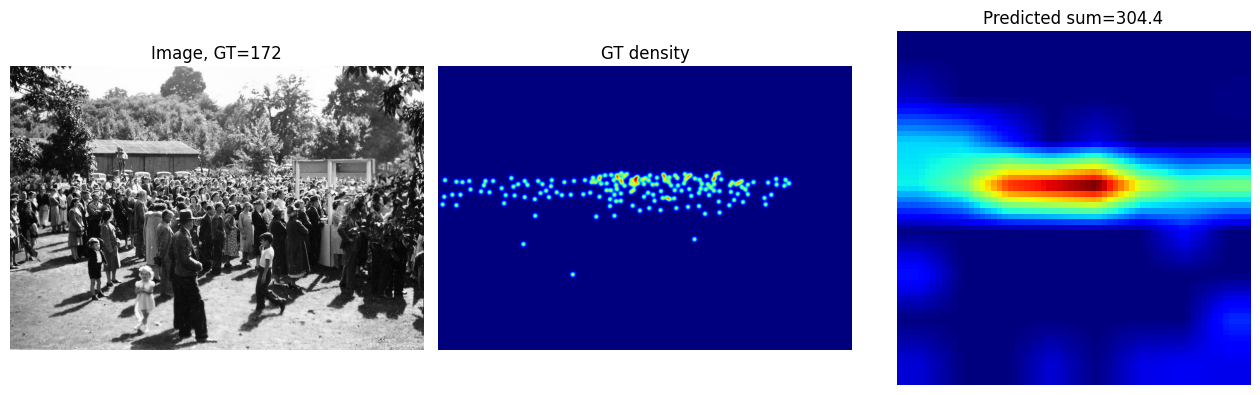

Saved Grad-CAM


  0%|          | 0/100 [00:00<?, ?it/s]

Saved LIME


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: rgb_image
Received: inputs=['Tensor(shape=(1, 256, 256, 3))']
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: rgb_image
Received: inputs=['Tensor(shape=(50, 256, 256, 3))']
  warnings.warn(msg)


Saved SHAP GradientExplainer map
Readable explanation: /content/crowd_risk_xai_results/explanations/EfficientNetB0/IMG_1/reason.txt


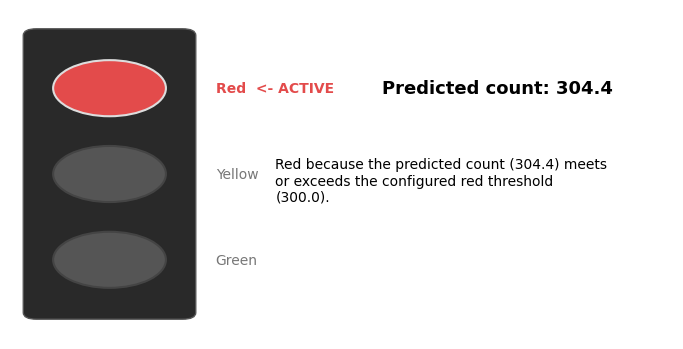

Human-readable model-output explanation (approximate)
Image: IMG_1.jpg
Predicted head count: 304.4
Count status: Red
Status reason: Red because the predicted count (304.4) meets or exceeds the configured red threshold (300.0).
Count rationale: the model's predicted density-map values are summed to obtain the image-level count.
Image-region rationale: Grad-CAM strongest response is in the middle-center region; Grad-CAM, LIME, SHAP attribution maps were generated to inspect regions associated with this count.
Interpretation limit: these approximate attributions do not establish causation, identify people, or explain crowd behavior.
Signal image: /content/crowd_risk_xai_results/explanations/EfficientNetB0/IMG_1/count_signal.png


In [11]:
# Explain one held-out image. Tune index and sampling settings for runtime.
IMAGE_INDEX=0; LIME_SAMPLES=100; SHAP_BACKGROUND=2
if not 0<=IMAGE_INDEX<len(test_pairs): raise IndexError('IMAGE_INDEX is outside test set')
pair=test_pairs[IMAGE_INDEX]; x,_,gt,image,_,gt_density=prepare(pair,chosen); model=loaded_models[chosen]
pred=model(x[None],training=False).numpy()[0,:,:,0]; count=float(pred.sum()); gradcam_region=None
xai_dir=OUTPUT_DIR/'explanations'/chosen/pair[0].stem; xai_dir.mkdir(parents=True,exist_ok=True)
fig,ax=plt.subplots(1,3,figsize=(13,4)); ax[0].imshow(image); ax[0].set_title(f'Image, GT={gt:.0f}'); ax[1].imshow(gt_density,cmap='jet'); ax[1].set_title('GT density'); ax[2].imshow(pred,cmap='jet'); ax[2].set_title(f'Predicted sum={count:.1f}'); [a.axis('off') for a in ax]; fig.tight_layout(); fig.savefig(xai_dir/'density_maps.png',dpi=200); plt.show()
status=risk_band(count)
if status=='Green': status_reason=f'Green because the predicted count ({count:.1f}) is below the configured green threshold ({GREEN_MAX:.1f}).'
elif status=='Yellow': status_reason=f'Yellow because the predicted count ({count:.1f}) is at least {GREEN_MAX:.1f} and below the configured red threshold ({YELLOW_MAX:.1f}).'
else: status_reason=f'Red because the predicted count ({count:.1f}) meets or exceeds the configured red threshold ({YELLOW_MAX:.1f}).'
pd.DataFrame([{'image':str(pair[0]),'ground_truth_count':gt,'predicted_count':count,'count_status':status,'status_reason':status_reason,'explanation_target':'sum of predicted density map'}]).to_csv(xai_dir/'summary.csv',index=False)

# Grad-CAM: use connected intermediate convolution output; if unavailable report incompatibility.
try:
    convs=[l for l in model.layers if isinstance(l,tf.keras.layers.Conv2D) and l.name!='density_native']
    if not convs: raise RuntimeError('No suitable intermediate Conv2D layer exposed in this model graph')
    layer=convs[-1]; gm=tf.keras.Model(model.input,[model.get_layer(layer.name).output,model.output])
    with tf.GradientTape() as tape:
        feat,density=gm(x[None],training=False); score=tf.reduce_sum(density)
    grad=tape.gradient(score,feat)
    if grad is None: raise RuntimeError('Selected convolution is not connected to predicted count')
    weights=tf.reduce_mean(grad,axis=(0,1,2)); cam=tf.maximum(tf.reduce_sum(feat[0]*weights,axis=-1),0).numpy(); cam/=cam.max()+1e-8
    cam=cv2.resize(cam,(image.shape[1],image.shape[0]))
    peak_y,peak_x=np.unravel_index(int(np.argmax(cam)),cam.shape)
    vertical=('upper','middle','lower')[min(2,peak_y*3//image.shape[0])]
    horizontal=('left','center','right')[min(2,peak_x*3//image.shape[1])]
    gradcam_region=f'{vertical}-{horizontal} region'
    plt.imsave(xai_dir/'gradcam.png',cam,cmap='jet'); print('Saved Grad-CAM')
except Exception as e:
    (xai_dir/'gradcam_unavailable.txt').write_text(str(e)); print('Grad-CAM unavailable:',e)

# LIME. LIME's perturbation predictor applies the exact model-specific preprocessing.
try:
    from lime import lime_image
    from skimage.segmentation import mark_boundaries
    def lime_predict(images):
        arr=np.stack([preprocess_image(np.clip(im,0,255).astype(np.uint8),chosen) for im in images]); return np.asarray(model(arr,training=False).numpy()).sum(axis=(1,2,3))[:,None]
    exp=lime_image.LimeImageExplainer().explain_instance(image.astype(np.double),lime_predict,labels=(0,),num_samples=LIME_SAMPLES)
    _,mask=exp.get_image_and_mask(0,positive_only=False,num_features=10,hide_rest=False)
    plt.imsave(xai_dir/'lime.png',mark_boundaries(image/255.0,mask)); print('Saved LIME')
except Exception as e:
    (xai_dir/'lime_unavailable.txt').write_text(str(e)); print('LIME unavailable:',e)

# SHAP GradientExplainer, with a small train-image background set.
try:
    import shap
    bg_pairs=train_pairs[:min(SHAP_BACKGROUND,len(train_pairs))]; bg=np.stack([prepare(p,chosen)[0] for p in bg_pairs])
    count_model=tf.keras.Model(model.input,tf.keras.layers.Lambda(lambda z:tf.reduce_sum(z,axis=[1,2,3]))(model.output))
    vals=shap.GradientExplainer(count_model,bg).shap_values(x[None])
    vals=np.asarray(vals[0] if isinstance(vals,list) else vals).squeeze()
    if vals.ndim==3: vals=np.abs(vals).mean(axis=-1)
    if vals.ndim!=2: raise ValueError(f'Unexpected SHAP result shape: {vals.shape}')
    vals=cv2.resize(vals.astype(np.float32),(image.shape[1],image.shape[0])); np.save(xai_dir/'shap_count.npy',vals)
    vmax=np.max(np.abs(vals))+1e-8; plt.imsave(xai_dir/'shap_count.png',vals,cmap='coolwarm',vmin=-vmax,vmax=vmax); print('Saved SHAP GradientExplainer map')
except Exception as e:
    (xai_dir/'shap_unavailable.txt').write_text(str(e)); print('SHAP unavailable:',e)
# Write a concise, human-readable explanation alongside the maps.
method_files={'Grad-CAM':'gradcam.png','LIME':'lime.png','SHAP':'shap_count.png'}
available_methods=[name for name,file in method_files.items() if (xai_dir/file).exists()]
unavailable_methods=[name for name in method_files if (xai_dir/(name.lower().replace('-', '')+'_unavailable.txt')).exists()]
reason_lines=[
    'Human-readable model-output explanation (approximate)',
    f'Image: {pair[0].name}',
    f'Predicted head count: {count:.1f}',
    f'Count status: {status}',
    f'Status reason: {status_reason}',
    "Count rationale: the model's predicted density-map values are summed to obtain the image-level count.",
    ('Image-region rationale: '+(f'Grad-CAM strongest response is in the {gradcam_region}; ' if gradcam_region else '')+', '.join(available_methods)+' attribution maps were generated to inspect regions associated with this count.') if available_methods else 'Image-region rationale: no attribution map was generated successfully; see the *_unavailable.txt files.',
    'Interpretation limit: these approximate attributions do not establish causation, identify people, or explain crowd behavior.'
]
if unavailable_methods: reason_lines.append('Unavailable attribution methods: '+', '.join(unavailable_methods)+'.')
(xai_dir/'reason.txt').write_text('\n'.join(reason_lines)+'\n',encoding='utf-8')
print('Readable explanation:',xai_dir/'reason.txt')

# Display the traffic-light status and text explanation directly in the notebook output.
from matplotlib.patches import Circle, FancyBboxPatch
signal_colors={'Red':'#e34b4b','Yellow':'#f2c230','Green':'#39ad62'}
fig,ax=plt.subplots(figsize=(7,3.6)); ax.set_xlim(0,1); ax.set_ylim(0,1); ax.axis('off')
ax.add_patch(FancyBboxPatch((0.04,0.08),0.22,0.84,boxstyle='round,pad=0.02',facecolor='#292929',edgecolor='#555555'))
for label,y in (('Red',0.76),('Yellow',0.50),('Green',0.24)):
    lit=label==status; color=signal_colors[label] if lit else '#555555'
    ax.add_patch(Circle((0.15,y),0.085,facecolor=color,edgecolor='#dddddd' if lit else '#444444',linewidth=1.5))
    ax.text(0.31,y,label+('  <- ACTIVE' if lit else ''),color=color if lit else '#777777',fontsize=10,va='center',fontweight='bold' if lit else 'normal')
ax.text(0.56,0.76,f'Predicted count: {count:.1f}',fontsize=13,fontweight='bold',va='center')
ax.text(0.40,0.48,'\n'.join(__import__('textwrap').wrap(status_reason,width=46)),fontsize=10,va='center')
fig.tight_layout(); fig.savefig(xai_dir/'count_signal.png',dpi=180,bbox_inches='tight'); plt.show()
print('\n'.join(reason_lines))
print('Signal image:',xai_dir/'count_signal.png')


## 11. Save final summary and review output files

The summary includes the fixed split, initialization seeds, mean validation-based model selection, per-seed test results, mean and standard deviation across runs, runtime/configuration metadata, thresholds, and the per-image `reason.txt` report. It contains only results produced by the executed cells. The multi-seed run can take several hours. Save or download the output directory after the run; in Colab it is temporary unless `OUTPUT_DIR` points into mounted Drive.


In [12]:
summary={'project':'Comparative Evaluation of Deep Learning Models for Crowd Counting','split_seed':SPLIT_SEED,'run_seeds':RUN_SEEDS,'image_size':IMAGE_SIZE,'density_size':DENSITY_SIZE,'epochs_budget':EPOCHS,'batch_size':BATCH_SIZE,'split_sizes':{'train':len(train_pairs),'validation':len(val_pairs),'test':len(test_pairs)},'selected_model_by_mean_validation_MAE':selection,'example_checkpoint_seed':best_seed,'runtime_by_seed':{str(s):json.loads((run_dirs[s]/'experiment.json').read_text())['runtime'] for s in RUN_SEEDS},'dataset_release':DATASET_RELEASE,'dataset_license_status':DATASET_LICENSE_STATUS,'per_seed_validation':{str(s):{m:float(model_metadata_by_seed[s][m]['best_validation_MAE']) for m in MODELS} for s in RUN_SEEDS},'test_metrics_mean_std':test_df.to_dict(orient='records'),'test_metrics_by_seed':test_run_rows,'explanation_report':str(OUTPUT_DIR/'explanations'/selection/test_pairs[IMAGE_INDEX][0].stem/'reason.txt'),'illustrative_thresholds_people':{'green_below':GREEN_MAX,'yellow_below':YELLOW_MAX,'red_at_or_above':YELLOW_MAX},'threshold_note':'Illustrative count bands, not a trained classifier or validated safety limits.','limitations':['Shared-protocol adaptations, not exact canonical implementations.','Attribution maps are approximate and generated for one image; they are not quantitatively evaluated or causal evidence.','Report hardware, package versions, completed epochs, and dataset provenance.','A small number of random seeds gives only a preliminary estimate of run variability.']}
(OUTPUT_DIR/'final_summary.json').write_text(json.dumps(summary,indent=2))
print('Completed outputs:')
for p in sorted(OUTPUT_DIR.rglob('*')):
    if p.is_file(): print(p.relative_to(OUTPUT_DIR))
print('Summary:',OUTPUT_DIR/'final_summary.json')


Completed outputs:
CSRNet_test_scatter.png
EfficientNetB0_test_scatter.png
MCNN_test_scatter.png
MobileNetV2_test_scatter.png
ResNet50_test_scatter.png
explanations/EfficientNetB0/IMG_1/count_signal.png
explanations/EfficientNetB0/IMG_1/density_maps.png
explanations/EfficientNetB0/IMG_1/gradcam.png
explanations/EfficientNetB0/IMG_1/lime.png
explanations/EfficientNetB0/IMG_1/reason.txt
explanations/EfficientNetB0/IMG_1/shap_count.npy
explanations/EfficientNetB0/IMG_1/shap_count.png
explanations/EfficientNetB0/IMG_1/summary.csv
final_summary.json
loss_curves.png
repeated_test_metrics_by_seed.csv
representative_examples/IMG_113.png
representative_examples/IMG_158.png
representative_examples/IMG_90.png
seed_42/CSRNet/best.keras
seed_42/CSRNet/epoch_001.keras
seed_42/CSRNet/epoch_003.keras
seed_42/CSRNet/epoch_005.keras
seed_42/CSRNet/epochs.csv
seed_42/CSRNet_test_predictions.csv
seed_42/EfficientNetB0/best.keras
seed_42/EfficientNetB0/epoch_001.keras
seed_42/EfficientNetB0/epoch_003.keras

In [13]:
from pathlib import Path

p = Path("/content/crowd_risk_xai_results/final_summary.json")
print(p.read_text())

{
  "project": "Comparative Evaluation of Deep Learning Models for Crowd Counting",
  "split_seed": 42,
  "run_seeds": [
    42,
    43,
    44,
    45,
    46
  ],
  "image_size": 256,
  "density_size": 64,
  "epochs_budget": 10,
  "batch_size": 2,
  "split_sizes": {
    "train": 240,
    "validation": 60,
    "test": 182
  },
  "selected_model_by_mean_validation_MAE": "EfficientNetB0",
  "example_checkpoint_seed": 46,
  "runtime_by_seed": {
    "42": {
      "python": "3.13.16",
      "tensorflow": "2.21.0",
      "numpy": "2.1.3",
      "scipy": "1.16.3",
      "opencv": "4.14.0",
      "pandas": "2.2.3",
      "scikit_learn": "1.6.1",
      "platform": "Linux-6.6.122+-x86_64-with-glibc2.39",
      "logical_cpu_count": 2,
      "memory_bytes": 13605822464,
      "gpus": [
        {
          "device": "/physical_device:GPU:0",
          "compute_capability": [
            7,
            5
          ],
          "device_name": "Tesla T4"
        }
      ]
    },
    "43": {
      "py